In [1]:
import ast
import os
import optuna
import ipynbname
import pandas as pd
import numpy as np
from optuna.exceptions import TrialPruned
from Functions.AutoCloud_V4_1 import *
from Functions.Utils import *
from Functions.Graphs import *
from Functions.TedaGraphs import *
from Functions.Utils_OPT_R2 import *

FileName = ipynbname.name()

# Configuração do experimento
FEEDBACK = 'symmetric'      # 'symmetric' (gradiente no passo atual) ou 'random' (ablação: RFLO + DFA)
WTAG, WTAP = False, False   # configuração principal: soma ponderada dos grânulos (eq. 36)
EOL = 0.3                   # limiar de fim de vida (EoL) do HI

def RunTag(feedback=None, wtaG=None, wtaP=None):
    # Uma pasta de resultados por configuração (feedback, wtaG, wtaP)
    feedback = FEEDBACK if feedback is None else feedback
    wtaG = WTAG if wtaG is None else wtaG
    wtaP = WTAP if wtaP is None else wtaP
    return f'{FileName}_{feedback}_G{int(wtaG)}P{int(wtaP)}'

def RefEoL(sig, eol, nI, mO, mode):
    '''
    Referência da RUL real baseada no limiar de EoL (eq. 12): RUL_real = iEoL - k_dado.
    O AutoCloud calcula rulR = ref - k, com k = j + 2 na iteração j, e o PrepareData
    alinha a iteração j à amostra k_dado = k0 + j. Logo ref = iEoL - k0 + 2.
    Retorna ref e J, o número de iterações com RUL real >= 1.
    '''
    sig = np.asarray(sig, dtype=float)
    if not np.any(sig <= eol): raise ValueError('O HI nunca atinge o limiar de EoL.')
    iEoL = int(np.argmax(sig <= eol))
    k0 = (max(nI, 1, mO) if mode in ('ahead', 1) else max(nI, 1)) - 1
    return iEoL - k0 + 2, iEoL - k0

def nOMax(sig, eol):
    '''
    Maior nO (modo 'ahead') para o qual o fluxo do PrepareData alcança a última amostra antes do EoL.
    A última janela fica em k = K - nO - 2 (o PrepareData descarta a última); exigir k >= iEoL - 1
    dá nO <= K - iEoL - 1, independente de nI e mO. No modo 'past' o fluxo sempre alcança o EoL.
    '''
    sig = np.asarray(sig, dtype=float)
    return len(sig) - int(np.argmax(sig <= eol)) - 1

out_path = os.path.join('Optimization', RunTag(), 'multi', 'Optimization.csv')
dfs = [pd.read_csv(out_path)] if os.path.exists(out_path) else []
RS = pd.read_excel(r'Dataset\RS.xlsx')
HI = pd.read_excel(r'Dataset\HI.xlsx')
sig = HI['PC1'].values

c:\Users\Usuario\Desktop\Python\Batteries_Prognostics\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


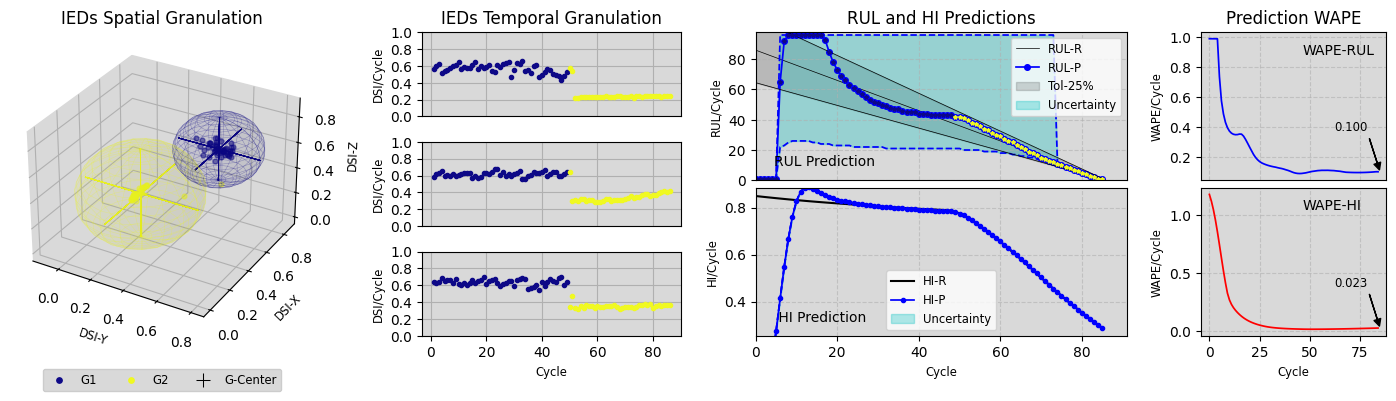

In [27]:
params = [3.5,28,[70],8,0,1,2,5,19,1,0]
m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

Rhos = np.linspace(1e-14,1e-4, 25)
cov, sp, Vpaper, Vused = np.array([]), np.array([]), np.array([]), np.array([])

for rho in Rhos:
    teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
                tau=τ,rho=rho,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO) 


    for j,_ in enumerate(X[:J]):
        teda.run(X[j])
        teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
        teda.WAPE_HI2(Y[j],Z[j])
        teda.Adapt(Y[j],Z[j])
    teda.RUL_Granularity()
    #teda.HI_Granularity()
    Vpaper = np.append(Vpaper,teda.Vpaper)
    Vused = np.append(Vused,teda.Vused)
    cov = np.append(cov,teda.cov)
    sp = np.append(sp,teda.sp)
PlotDSI_3D_PLT(teda,xi=0)


In [28]:
PlotSeriesPLY(xSeries=[Rhos,Rhos], ySeries=[Vpaper,Vused],names=['Vpaper','Vused'])
PlotSeriesPLY(xSeries=[Rhos,Rhos], ySeries=[cov,sp],names=['cov','sp'])

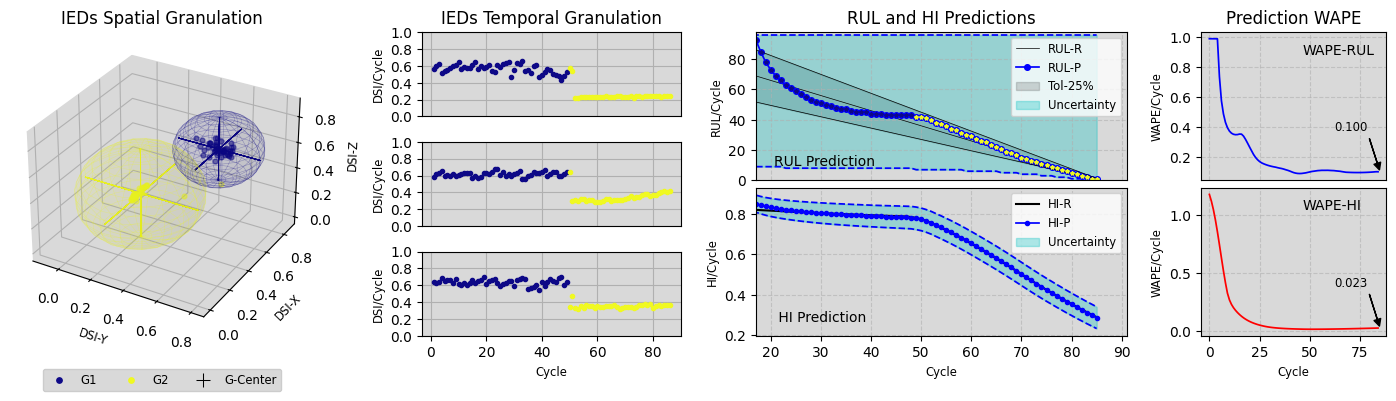

In [33]:
m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
               tau=τ,rho=1e-2,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO) 


for j,_ in enumerate(X[:J]):
    teda.run(X[j])
    teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
    teda.WAPE_HI2(Y[j],Z[j])
    teda.Adapt(Y[j],Z[j])

#teda.c = np.append(teda.c,teda.gm)  
PlotDSI_3D_PLT(teda)

In [37]:
#PlotSeriesPLY(ySeries=[teda.hiR,teda.hiP,teda.hiL,teda.hiU])
PlotSeriesPLY(ySeries=[teda.hiP-teda.hiL,teda.hiU-teda.hiP])

#PlotSeriesPLY(ySeries=[teda.rulR,teda.rulP,teda.rulL,teda.rulU])

In [13]:
print('rulP:',teda.rulP)
print('rulL:',teda.rulL)
print('rulU:',teda.rulU)

# Coerência dos intervalos (eRNN_GD_R3: aritmética intervalar exata) e truncamento em lim
n = len(teda.rulP)
print(f"\nHI : hiP fora de [hiL, hiU]  : {int(np.sum((teda.hiP < teda.hiL) | (teda.hiP > teda.hiU)))}/{len(teda.hiP)}")
print(f"RUL: rulP fora de [rulL, rulU]: {int(np.sum((teda.rulP < teda.rulL) | (teda.rulP > teda.rulU)))}/{n}")
print(f"RUL truncada em lim (não atinge o EoL) -> inferior: {teda.rulCapL.sum()}/{n} | pontual: {teda.rulCapP.sum()}/{n} | superior: {teda.rulCapU.sum()}/{n}")

rulP: [ 1.  1.  1.  1.  1.  1.  1. 37. 46. 54. 63. 73. 84. 85. 85. 85. 85. 80.
 72. 66. 61. 58. 55. 53. 52. 50. 49. 48. 47. 46. 45. 43. 42. 41. 40. 39.
 38. 38. 37. 36. 35. 34. 33. 32. 31. 30. 29. 28. 27. 26. 25. 24. 23. 22.
 21. 20. 19. 18. 17. 16. 15. 14. 13. 12. 10.  9.  8.  7.  6.  5.  4.  3.
  2.  1.  1.]
rulL: [ 1.  1.  1.  1.  1.  1.  1.  1. 68. 85. 85. 85. 85. 85. 85. 85. 85. 85.
 85. 85. 85. 85. 85. 85. 85. 85. 84. 83. 82. 80. 79. 77. 76. 75. 74. 74.
 74. 75. 75. 76. 76. 77. 77. 77. 78. 80. 85. 85. 85. 85. 85. 85. 85. 85.
 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85.
  1.  1.  1.]
rulU: [ 1.  1.  1.  1.  1. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85.
 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85.
 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85.
 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85. 85.
 85. 85. 85.]
